In [131]:
# pip install langchain_openai

In [132]:
from langgraph.graph import StateGraph, START, END
from langchain_core.messages import SystemMessage, HumanMessage
from pydantic import BaseModel, Field # pydantic helps us to have structured output from the model, it helps us get the custom output we want from the model.
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv

load_dotenv()

#langchain specific langchain openai model

#e.g.
# from langchain_gemini from ChatGemini
# from langchain_openai import ChatOpenAI

True

In [133]:
client = ChatOpenAI(model="gpt-4o-mini")
# llm_gemini = ChatGemini(model="gemini-1.5-turbo", temperature=0.5, max_tokens=1000)

In [134]:
client.invoke([SystemMessage(content="You are a helpful assistant."), HumanMessage(content="Hello!")])

AIMessage(content='Hello! How can I assist you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 9, 'prompt_tokens': 19, 'total_tokens': 28, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_0e7150ae59', 'id': 'chatcmpl-EgZQfqKsSzf6P2e6a9D0s68mzusfe', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1a7af-b281-75cb-a713-3b150348080c-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 19, 'output_tokens': 9, 'total_tokens': 28, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})

In [135]:
#state definitions
# a sentiment based response generator, that takes a tweet and generates a response based on the sentiment of the tweet
from typing import TypedDict, Literal
# working memory defition
class SentimentState(TypedDict):
    original_tweet:str
    sentiment: str
    confidence: float
    response_tweet: str

In [136]:
class SentimentAnalysis(BaseModel):
    sentiment: Literal["positive","negative"]= Field(description="the sentiment classification either positive or negative")
    confidence: float = Field(ge=0.0,le=1.0, description="the confidence for the sentiment classification, a float between 0.0 and 1.0")
    reason: str = Field(description="brief explanation")
    

In [137]:
structured_llm= client.with_structured_output(SentimentAnalysis)
structured_llm.invoke([SystemMessage(content="You are a helpful assistant."), HumanMessage(content="Hello!")])

SentimentAnalysis(sentiment='positive', confidence=0.95, reason="The greeting 'Hello!' indicates a friendly and positive sentiment.")

In [138]:
#node 1
def analyze_sentiment(state: SentimentState) -> SentimentState:
    """
    Analyze the sentiment of a given tweet.
    """
    tweet = state['original_tweet']

    messages=[
        SystemMessage("analyse sentiment of the tweet and provide the structured output. Use the scale of 0 to 1.0 for confidence."),
        HumanMessage(tweet)
    ]
    # Use the LLM to analyze the sentiment of the original tweet
    response = structured_llm.invoke(messages)
    
    state['sentiment'] = response.sentiment
    state['confidence'] = response.confidence
    
    return state

In [139]:
#test analyse sentiment node
print(analyze_sentiment({'original_tweet': "very bad Product"}))

{'original_tweet': 'very bad Product', 'sentiment': 'negative', 'confidence': 0.95}


In [140]:
#node 3 
def generate_positive_response(state: SentimentState) -> SentimentState:
    """
    Generate a positive response to based on the tweet if the sentiment is positive.
    """
    messages=[
        SystemMessage("You are a helpful assistant. Generate a positive response under 200 characters to the tweet."),
        HumanMessage(state['original_tweet'])
    ]
    response = client.invoke(messages)
    state['response_tweet'] = response.content.strip()
    return state

In [141]:
# test positive response node
print(generate_positive_response({'original_tweet': "I love this product!", 'sentiment': 'positive', 'confidence': 0.95, 'response_tweet': ''}))

{'original_tweet': 'I love this product!', 'sentiment': 'positive', 'confidence': 0.95, 'response_tweet': "That's amazing to hear! What do you love most about it? 😊"}


In [142]:
#node 4
def generate_emphatic_response(state: SentimentState) -> SentimentState:
    """
    Generate a emphatic response to the tweet if the sentiment is negative.
    """
    messages=[
        SystemMessage("You are a helpful assistant. Generate a emphatic response under 200 characters to the tweet."),
        HumanMessage(state['original_tweet'])
    ]
    response = client.invoke(messages)
    state['response_tweet'] = response.content.strip()
    return state

In [143]:
#test negative response node
print(generate_emphatic_response({'original_tweet': "I hate this product!", 'sentiment': 'negative', 'confidence': 0.95, 'response_tweet': ''}))

{'original_tweet': 'I hate this product!', 'sentiment': 'negative', 'confidence': 0.95, 'response_tweet': "I'm really sorry to hear that! Your frustration is valid. Have you had a chance to share your feedback with the company? They may want to know how to improve!"}


In [144]:
#define the nodes edges and states with graph builder
builder = StateGraph(SentimentState)

builder.add_node("analyze_sentiment", analyze_sentiment)
builder.add_node("generate_positive_response", generate_positive_response)
builder.add_node("generate_emphatic_response", generate_emphatic_response)


In [145]:
# this has not been made as node because it is a routing function, not a processing node
def route_by_sentiment(state: SentimentState) -> str:
    print("Current state in route_by_sentiment:", state)
    if state['sentiment'] == 'positive':
        return "generate_positive_response"
    elif state['sentiment'] == 'negative':
        return "generate_emphatic_response"
    else:
        raise ValueError("Invalid sentiment value")

In [146]:
# test routing function
print(route_by_sentiment({'original_tweet': "I love this product!", 'sentiment': 'positive', 'confidence': 0.95, 'response_tweet': ''}))

Current state in route_by_sentiment: {'original_tweet': 'I love this product!', 'sentiment': 'positive', 'confidence': 0.95, 'response_tweet': ''}
generate_positive_response


In [ ]:
builder.add_node("route_by_sentiment", route_by_sentiment)

builder.add_edge(START, "analyze_sentiment")
#builder.add_edge("analyze_sentiment", "route_by_sentiment")
# we can't used add_edge with routing with route_by_sentiment because then it is not conditional and route_by_sentiment will call both nodes one by one
# builder.add_edge("route_by_sentiment", "generate_positive_response")
# builder.add_edge("route_by_sentiment", "generate_emphatic_response")

builder.add_conditional_edges("analyze_sentiment",route_by_sentiment,["generate_positive_response","generate_emphatic_response"])
builder.add_edge("generate_positive_response", END)
builder.add_edge("generate_emphatic_response", END)

In [128]:
compiled_builder = builder.compile()

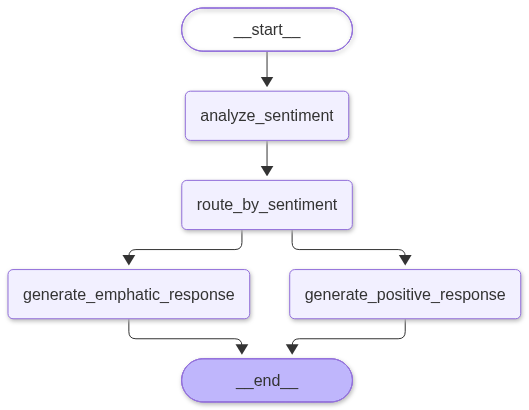

In [129]:
compiled_builder

In [130]:
compiled_builder.invoke({'original_tweet': "I love this product!"})

Current state in route_by_sentiment: {'original_tweet': 'I love this product!', 'sentiment': 'positive', 'confidence': 0.95}


InvalidUpdateError: Expected dict, got generate_positive_response
For troubleshooting, visit: https://docs.langchain.com/oss/python/langgraph/errors/INVALID_GRAPH_NODE_RETURN_VALUE

In [108]:
compiled_builder.invoke({'original_tweet': "this is not a good product!"})

Current state in route_by_sentiment: {'original_tweet': 'this is not a good product!', 'sentiment': 'negative', 'confidence': 0.95}


{'original_tweet': 'this is not a good product!',
 'sentiment': 'negative',
 'confidence': 0.95,
 'response_tweet': 'I hear you! It’s frustrating when a product doesn’t meet expectations. What specifically didn’t work for you? Your feedback can help improve it!'}

In [109]:
tweet = "very bad Product"

messages=[
    SystemMessage("analyse sentiment of the tweet and provide the structured output. Use the scale of 0 to 1.0 for confidence."),
    HumanMessage(tweet)
]

client.invoke(messages)

AIMessage(content='{\n  "sentiment": "negative",\n  "confidence": 0.95\n}', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 19, 'prompt_tokens': 39, 'total_tokens': 58, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_d657ac4213', 'id': 'chatcmpl-EgZFnktOaI8WgXT25OQfpymGJSKqe', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1a7a5-6edf-7138-b5d0-917f358d3486-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 39, 'output_tokens': 19, 'total_tokens': 58, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 're

In [ ]:
# conditional routing one is workflow based one but it not fully smart in sense here it is not maintaining memory once the workflow is completed, it will not remember the previous state. It is a simple workflow based routing.

In [ ]:
#we can have multiple states but depends on our use case, we can have multiple states and multiple nodes and multiple routing functions. It is a simple workflow based routing.